<a href="https://colab.research.google.com/github/AmassableMovie4/Liquidity/blob/main/Liquidity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install yfinance pandas matplotlib seaborn pandas_ta torch torchdiffeq scikit-learn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.1/115.1 kB 3.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for pandas_ta: filename=pandas_ta-0.3.14b0-py3-none-any.whl size=218909 sha256=75016fc3b9cfa2b9895c3f4f8562712e5e8932d2e1c26d79eaaf723cce9a4147
  Stored in directory: /root/.cache/pip/wheels/69/00/ac/f7fa862c34b0e2ef320175100c233377b4c558944f12474cf0
Successfully built pandas_ta


In [2]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pandas_ta as ta
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torchdiffeq import odeint
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from datetime import datetime

# For better plot aesthetics
sns.set(style="darkgrid")


In [3]:
def fetch_stock_data(ticker, period='10y'):
    """
    Fetches historical stock data for a given ticker symbol.

    Parameters:
        ticker (str): Stock ticker symbol (e.g., 'AAPL', 'TSLA').
        period (str): Duration of historical data (default is '20y' for 20 years).

    Returns:
        pd.DataFrame: DataFrame containing historical stock data.
    """
    try:
        stock = yf.Ticker(ticker)
        df = stock.history(period=period)
        df.reset_index(inplace=True)  # Reset index to have 'Date' as a column
        return df
    except Exception as e:
        print(f"Error fetching data for {ticker}: {e}")
        return None


In [4]:
# Fetch data
tsla_data = fetch_stock_data('TSLA')
aapl_data = fetch_stock_data('AAPL')

# Verify data fetching
if tsla_data is not None:
    print("Tesla (TSLA) data fetched successfully.")
if aapl_data is not None:
    print("Apple (AAPL) data fetched successfully.")


Tesla (TSLA) data fetched successfully.
Apple (AAPL) data fetched successfully.


In [5]:
def display_head_tail(df, ticker):
    """
    Displays the head and tail of the DataFrame.

    Parameters:
        df (pd.DataFrame): The stock data DataFrame.
        ticker (str): The ticker symbol for labeling.
    """
    print(f"\n===== {ticker} Data Head =====")
    print(df.head())

    print(f"\n===== {ticker} Data Tail =====")
    print(df.tail())


In [6]:
# Display head and tail for TSLA
if tsla_data is not None:
    display_head_tail(tsla_data, 'TSLA')

# Display head and tail for AAPL
if aapl_data is not None:
    display_head_tail(aapl_data, 'AAPL')



===== TSLA Data Head =====
                       Date       Open       High        Low      Close  \
0 2014-10-20 00:00:00-04:00  15.114667  15.493333  15.034000  15.364667   
1 2014-10-21 00:00:00-04:00  15.618000  15.692667  15.386667  15.689333   
2 2014-10-22 00:00:00-04:00  15.546000  15.826000  15.370667  15.406667   
3 2014-10-23 00:00:00-04:00  15.644000  15.752000  15.466667  15.686000   
4 2014-10-24 00:00:00-04:00  15.751333  15.853333  15.413333  15.682667   

     Volume  Dividends  Stock Splits  
0  52416000        0.0           0.0  
1  61954500        0.0           0.0  
2  61749000        0.0           0.0  
3  52386000        0.0           0.0  
4  51949500        0.0           0.0  

===== TSLA Data Tail =====
                          Date        Open        High         Low  \
2512 2024-10-14 00:00:00-04:00  220.130005  221.910004  213.740005   
2513 2024-10-15 00:00:00-04:00  220.009995  224.259995  217.119995   
2514 2024-10-16 00:00:00-04:00  221.399994  222.8

In [7]:
def summary_statistics(df, ticker):
    """
    Displays summary statistics of the DataFrame.

    Parameters:
        df (pd.DataFrame): The stock data DataFrame.
        ticker (str): The ticker symbol for labeling.
    """
    print(f"\n===== {ticker} Summary Statistics =====")
    print(df.describe())


In [8]:
# Summary statistics for TSLA
if tsla_data is not None:
    summary_statistics(tsla_data, 'TSLA')

# Summary statistics for AAPL
if aapl_data is not None:
    summary_statistics(aapl_data, 'AAPL')



===== TSLA Summary Statistics =====
              Open         High          Low        Close        Volume  \
count  2517.000000  2517.000000  2517.000000  2517.000000  2.517000e+03   
mean    109.098140   111.477579   106.557539   109.070789  1.120387e+08   
std     109.830415   112.256660   107.166161   109.736809  7.411403e+07   
min       9.488000    10.331333     9.403333     9.578000  1.062000e+07   
25%      16.770666    17.000000    16.553333    16.771334  6.658350e+07   
50%      24.106667    24.467333    23.600000    23.980000  9.271320e+07   
75%     215.259995   219.800003   209.513336   214.979996  1.295565e+08   
max     411.470001   414.496674   405.666656   409.970001  9.140820e+08   

       Dividends  Stock Splits  
count     2517.0   2517.000000  
mean         0.0      0.003178  
std          0.0      0.116204  
min          0.0      0.000000  
25%          0.0      0.000000  
50%          0.0      0.000000  
75%          0.0      0.000000  
max          0.0      5

In [9]:
def plot_closing_prices(df, ticker):
    """
    Plots the closing prices over time.

    Parameters:
        df (pd.DataFrame): The stock data DataFrame.
        ticker (str): The ticker symbol for labeling.
    """
    plt.figure(figsize=(8, 4))
    plt.plot(df['Date'], df['Close'], label='Closing Price')
    plt.title(f'{ticker} Closing Prices Over 10 Years')
    plt.xlabel('Date')
    plt.ylabel('Price ($)')
    plt.legend()
    plt.show()


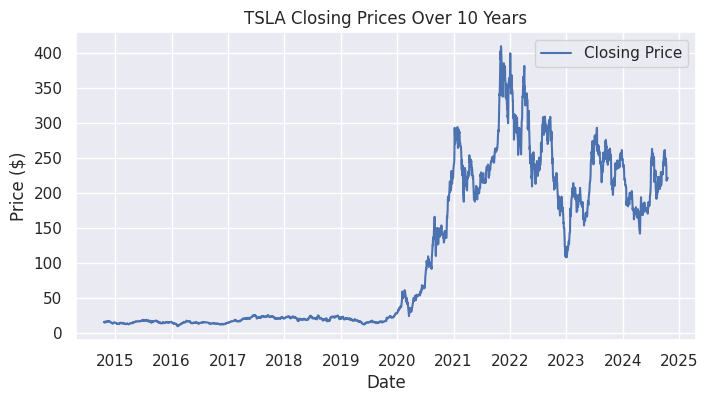

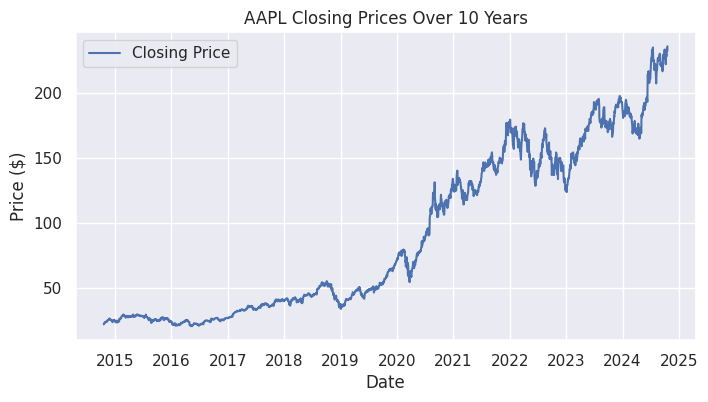

In [10]:
# Plot closing prices for TSLA
if tsla_data is not None:
    plot_closing_prices(tsla_data, 'TSLA')

# Plot closing prices for AAPL
if aapl_data is not None:
    plot_closing_prices(aapl_data, 'AAPL')


In [11]:
def add_moving_averages(df, short_window=50, long_window=200):
    """
    Adds short-term and long-term moving averages to the DataFrame.

    Parameters:
        df (pd.DataFrame): The stock data DataFrame.
        short_window (int): Window size for short-term MA (default is 50).
        long_window (int): Window size for long-term MA (default is 200).

    Returns:
        pd.DataFrame: DataFrame with added moving averages.
    """
    df[f'MA_{short_window}'] = df['Close'].rolling(window=short_window).mean()
    df[f'MA_{long_window}'] = df['Close'].rolling(window=long_window).mean()
    return df


In [12]:
def plot_moving_averages(df, ticker, short_window=50, long_window=200):
    """
    Plots closing prices along with moving averages.

    Parameters:
        df (pd.DataFrame): The stock data DataFrame with moving averages.
        ticker (str): The ticker symbol for labeling.
        short_window (int): Window size for short-term MA.
        long_window (int): Window size for long-term MA.
    """
    plt.figure(figsize=(8, 4))
    plt.plot(df['Date'], df['Close'], label='Closing Price')
    plt.plot(df['Date'], df[f'MA_{short_window}'], label=f'MA_{short_window}')
    plt.plot(df['Date'], df[f'MA_{long_window}'], label=f'MA_{long_window}')
    plt.title(f'{ticker} Closing Prices with Moving Averages')
    plt.xlabel('Date')
    plt.ylabel('Price ($)')
    plt.legend()
    plt.show()


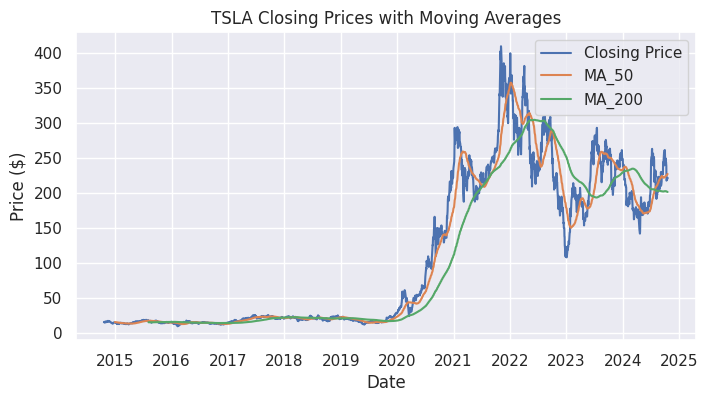

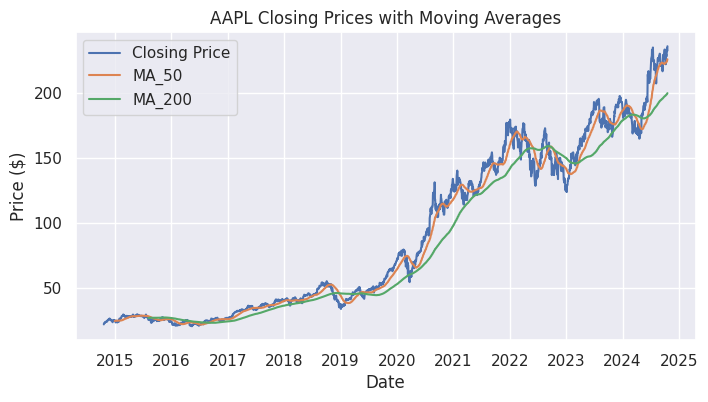

In [13]:
# Add and plot moving averages for TSLA
if tsla_data is not None:
    tsla_data = add_moving_averages(tsla_data)
    plot_moving_averages(tsla_data, 'TSLA')

# Add and plot moving averages for AAPL
if aapl_data is not None:
    aapl_data = add_moving_averages(aapl_data)
    plot_moving_averages(aapl_data, 'AAPL')


In [14]:
def plot_volume(df, ticker, color='orange'):
    """
    Plots the trading volume over time.

    Parameters:
        df (pd.DataFrame): The stock data DataFrame.
        ticker (str): The ticker symbol for labeling.
    """
    plt.figure(figsize=(14, 7))
    plt.bar(df['Date'], df['Volume'], label='Volume', color=color, width=30)
    plt.title(f'{ticker} Trading Volume Over 10 Years')
    plt.xlabel('Date')
    plt.ylabel('Volume')
    plt.legend()
    plt.show()


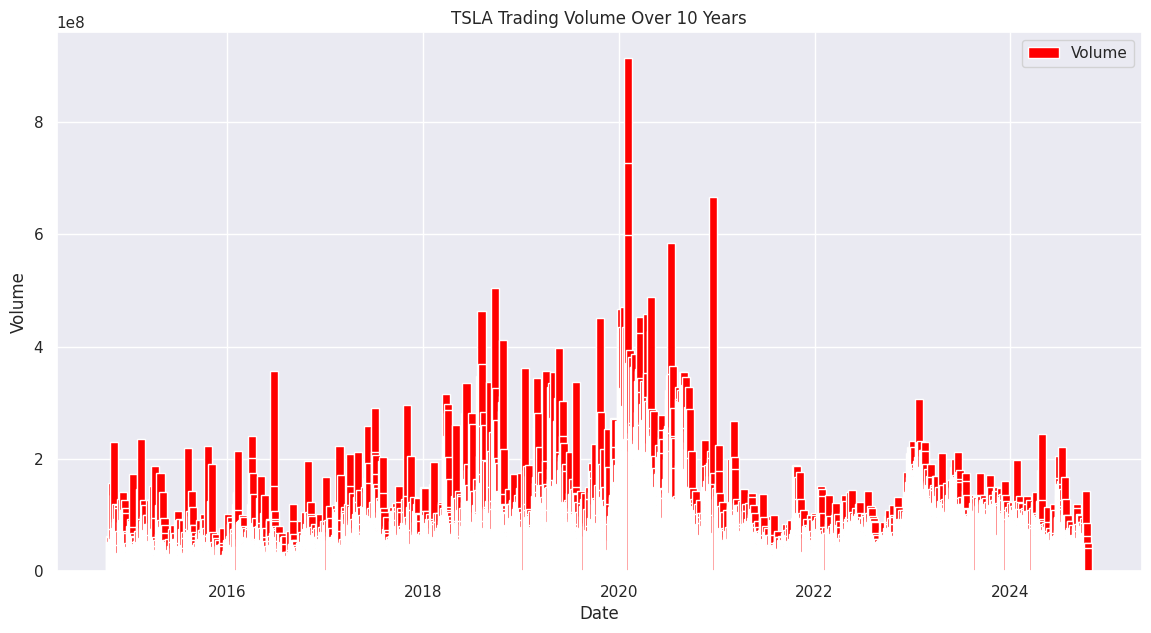

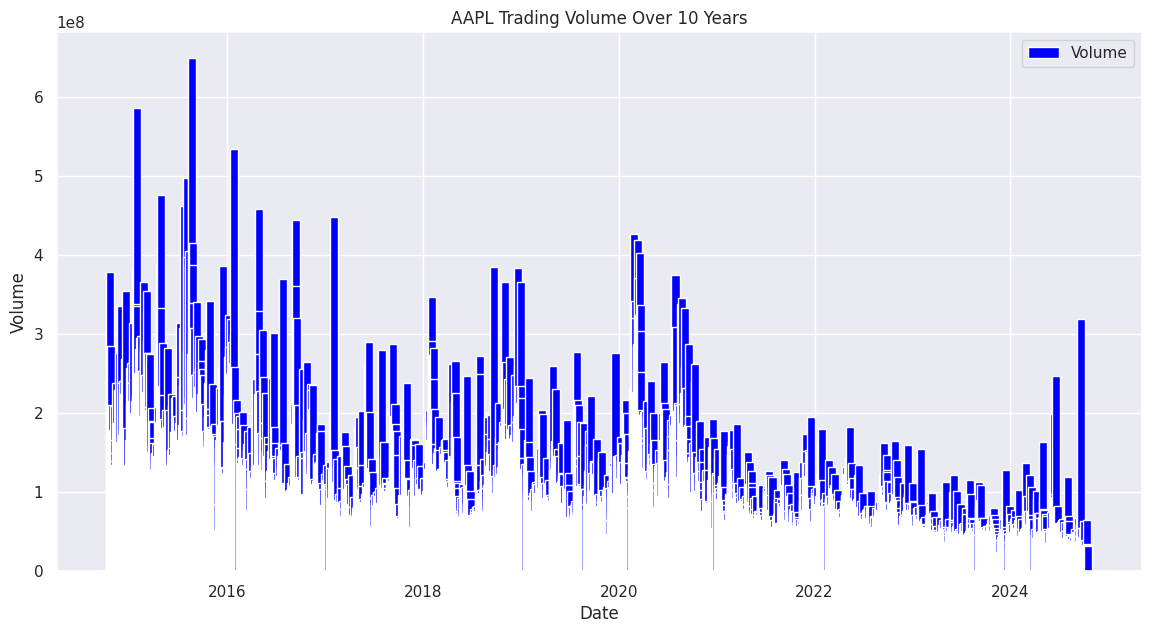

In [15]:
# Plot trading volume for TSLA
if tsla_data is not None:
    plot_volume(tsla_data, 'TSLA', color='red')

# Plot trading volume for AAPL
if aapl_data is not None:
    plot_volume(aapl_data, 'AAPL', color='blue')


In [16]:
def calculate_technical_indicators(df):
    """
    Calculates various technical indicators and adds them to the DataFrame.

    Parameters:
        df (pd.DataFrame): The stock data DataFrame.

    Returns:
        pd.DataFrame: DataFrame with added technical indicators.
    """
    # Moving Averages
    df = add_moving_averages(df)

    # Relative Strength Index (RSI)
    df['RSI'] = ta.rsi(df['Close'], length=14)

    # Moving Average Convergence Divergence (MACD)
    macd = ta.macd(df['Close'], fast=12, slow=26, signal=9)
    df = pd.concat([df, macd], axis=1)

    # Bollinger Bands
    bollinger = ta.bbands(df['Close'], length=20, std=2)
    df = pd.concat([df, bollinger], axis=1)

    # On-Balance Volume (OBV)
    df['OBV'] = ta.obv(df['Close'], df['Volume'])

    # Drop NaN values created by technical indicators
    df.dropna(inplace=True)

    return df


In [17]:
# Calculate technical indicators for TSLA
if tsla_data is not None:
    tsla_data = calculate_technical_indicators(tsla_data)

# Calculate technical indicators for AAPL
if aapl_data is not None:
    aapl_data = calculate_technical_indicators(aapl_data)


In [18]:
def display_technical_indicators(df, ticker, indicators=['RSI', 'MACD_12_26_9', 'MACDh_12_26_9', 'MACDs_12_26_9', 'BBL_20_2.0', 'BBM_20_2.0', 'BBU_20_2.0', 'OBV']):
    """
    Displays selected technical indicators from the DataFrame.

    Parameters:
        df (pd.DataFrame): The stock data DataFrame with technical indicators.
        ticker (str): The ticker symbol for labeling.
        indicators (list): List of technical indicators to display.
    """
    print(f"\n===== {ticker} Technical Indicators =====")
    print(df[indicators].tail())


In [19]:
# Display technical indicators for TSLA
if tsla_data is not None:
    display_technical_indicators(tsla_data, 'TSLA')

# Display technical indicators for AAPL
if aapl_data is not None:
    display_technical_indicators(aapl_data, 'AAPL')



===== TSLA Technical Indicators =====
            RSI  MACD_12_26_9  MACDh_12_26_9  MACDs_12_26_9  BBL_20_2.0  \
2512  39.620187      0.413335      -4.600871       5.014205  218.473921   
2513  39.915148     -1.018902      -4.826486       3.807584  216.789187   
2514  41.242077     -1.989015      -4.637279       2.648264  215.671764   
2515  40.998309     -2.761509      -4.327818       1.566309  212.877898   
2516  41.819776     -3.257411      -3.858976       0.601565  210.796957   

      BBM_20_2.0  BBU_20_2.0           OBV  
2512  243.736500  268.999078  1.615735e+10  
2513  243.321500  269.853814  1.622034e+10  
2514  243.028001  270.384238  1.626997e+10  
2515  241.876501  270.875104  1.621927e+10  
2516  241.057301  271.317644  1.625992e+10  

===== AAPL Technical Indicators =====
            RSI  MACD_12_26_9  MACDh_12_26_9  MACDs_12_26_9  BBL_20_2.0  \
2512  58.135717      1.419035       0.230568       1.188467  219.654767   
2513  61.199897      1.815958       0.501993       

In [20]:
def plot_correlation_matrix(df, ticker):
    """
    Plots the correlation matrix of the DataFrame.

    Parameters:
        df (pd.DataFrame): The stock data DataFrame with technical indicators.
        ticker (str): The ticker symbol for labeling.
    """
    plt.figure(figsize=(12, 10))
    correlation = df.corr()
    sns.heatmap(correlation, annot=True, fmt=".2f", cmap='coolwarm')
    plt.title(f'{ticker} Correlation Matrix')
    plt.show()


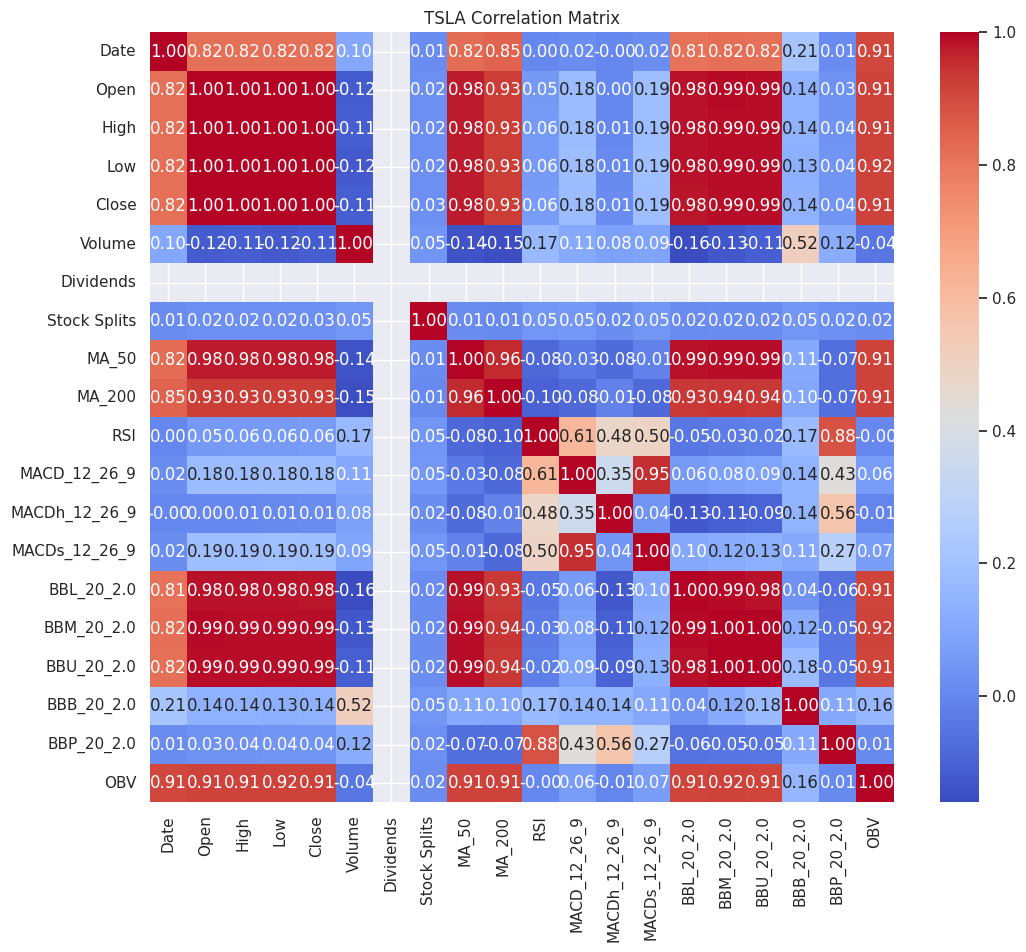

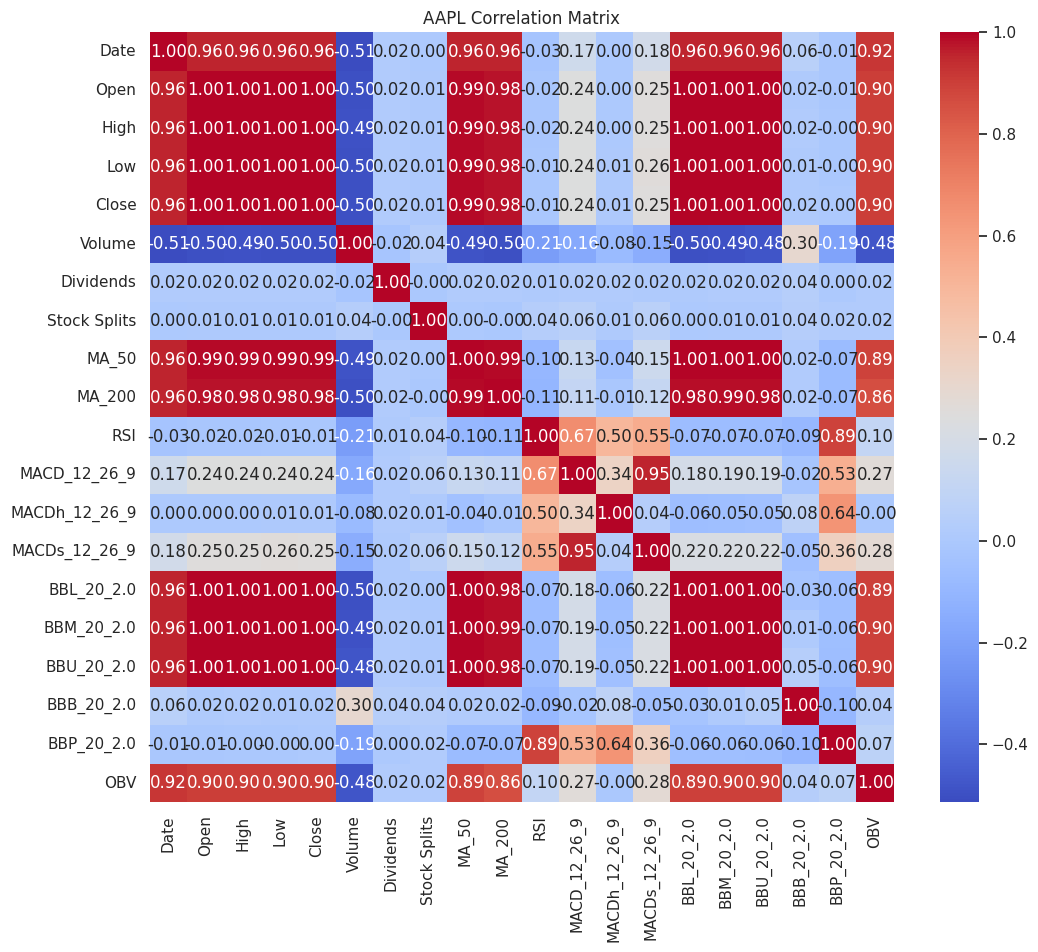

In [21]:
# Plot correlation matrix for TSLA
if tsla_data is not None:
    plot_correlation_matrix(tsla_data, 'TSLA')

# Plot correlation matrix for AAPL
if aapl_data is not None:
    plot_correlation_matrix(aapl_data, 'AAPL')


# Select ticker to train on
train_ticker = 'TSLA'

print(f"\nTraining model for {train_ticker}...")

# Train the model
train_model(model, criterion, optimizer,
            X_train[train_ticker], Y_train[train_ticker],
            X_val[train_ticker], Y_val[train_ticker],
            NUM_EPOCHS, device)

print("\nTraining completed.")


Using device: cuda

Training model for TSLA...
Epoch [1/50], Training Loss: 0.089528, Validation Loss: 0.059852
Epoch [5/50], Training Loss: 0.030298, Validation Loss: 0.011659
Epoch [10/50], Training Loss: 0.004443, Validation Loss: 0.013680
Epoch [15/50], Training Loss: 0.008750, Validation Loss: 0.023441
Epoch [20/50], Training Loss: 0.002538, Validation Loss: 0.005188
Epoch [25/50], Training Loss: 0.002009, Validation Loss: 0.001877
Epoch [30/50], Training Loss: 0.002303, Validation Loss: 0.001603
Epoch [35/50], Training Loss: 0.001301, Validation Loss: 0.001980
Epoch [40/50], Training Loss: 0.001015, Validation Loss: 0.004229
Epoch [45/50], Training Loss: 0.001155, Validation Loss: 0.004115
Epoch [50/50], Training Loss: 0.000873, Validation Loss: 0.002951

Training completed.

Validation RMSE for TSLA: 21.75


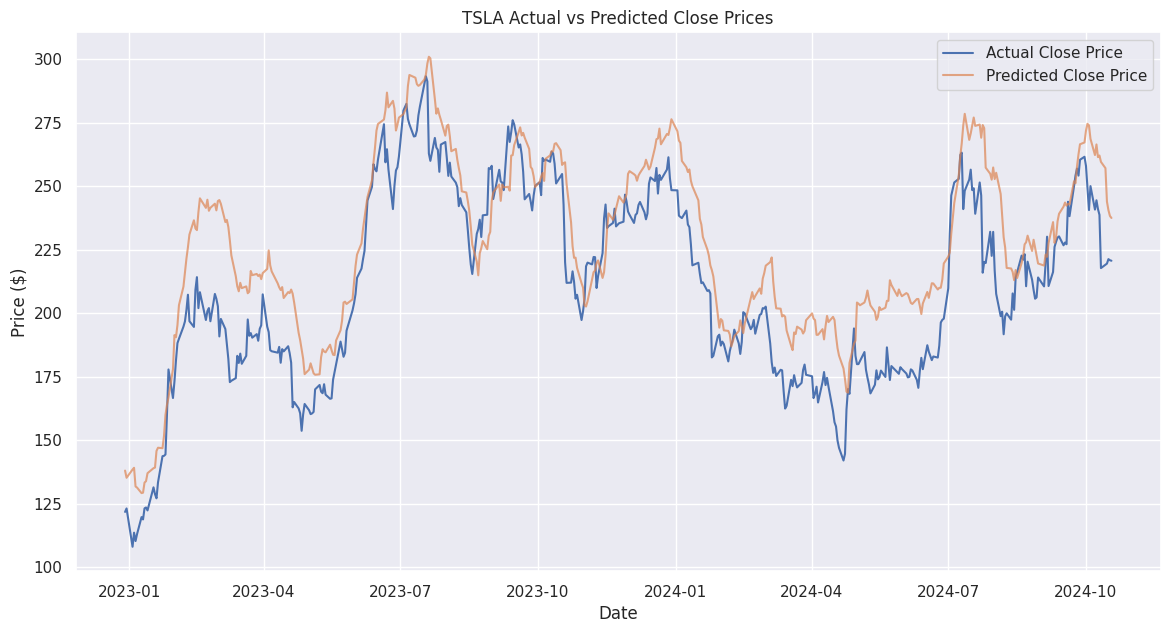

In [76]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pandas_ta as ta
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torchdiffeq import odeint
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from datetime import datetime

# Set plot aesthetics
sns.set(style="darkgrid")

# Function to fetch stock data
def fetch_stock_data(ticker, period='10y'):
    try:
        stock = yf.Ticker(ticker)
        df = stock.history(period=period)
        df.reset_index(inplace=True)
        return df
    except Exception as e:
        print(f"Error fetching data for {ticker}: {e}")
        return None

# Function for feature engineering
def feature_engineering(df):
    # Moving Averages
    df['MA_50'] = df['Close'].rolling(window=50).mean()
    df['MA_200'] = df['Close'].rolling(window=200).mean()

    # Relative Strength Index (RSI)
    df['RSI_14'] = ta.rsi(df['Close'], length=14)

    # Moving Average Convergence Divergence (MACD)
    macd = ta.macd(df['Close'], fast=12, slow=26, signal=9)
    df = pd.concat([df, macd], axis=1)

    # Bollinger Bands
    bollinger = ta.bbands(df['Close'], length=20, std=2)
    df = pd.concat([df, bollinger], axis=1)

    # On-Balance Volume (OBV)
    df['OBV'] = ta.obv(df['Close'], df['Volume'])

    # Drop rows with NaN values created by technical indicators
    df.dropna(inplace=True)

    return df

# Function to create sequences
def create_sequences(data, seq_length):
    X = []
    Y = []
    for i in range(len(data) - seq_length):
        X.append(data[i:i + seq_length])
        Y.append(data[i + seq_length, 0])  # Predicting 'Close' price
    return np.array(X), np.array(Y)

# Define stock symbols
tickers = ['TSLA', 'AAPL']

# Initialize dictionaries to store data
stock_data = {}
technical_data = {}
scaled_data = {}
scalers = {}
X_train, Y_train = {}, {}
X_val, Y_val = {}, {}

# Sequence length for the model
SEQ_LENGTH = 50

for ticker in tickers:
    # Fetch data
    df = fetch_stock_data(ticker)
    if df is not None:
        stock_data[ticker] = df
        # Feature Engineering
        df = feature_engineering(df)
        technical_data[ticker] = df
        # Select features
        features = ['Close', 'MA_50', 'MA_200', 'RSI_14', 'MACD_12_26_9', 'MACDh_12_26_9',
                    'MACDs_12_26_9', 'BBL_20_2.0', 'BBM_20_2.0', 'BBU_20_2.0',
                    'OBV']
        data = df[features].values
        # Scaling
        scaler = MinMaxScaler(feature_range=(0, 1))
        scaled = scaler.fit_transform(data)
        scaled_data[ticker] = scaled
        scalers[ticker] = scaler
        # Create sequences
        X, Y = create_sequences(scaled, SEQ_LENGTH)
        # Split into training and validation sets (80-20)
        train_size = int(len(X) * 0.8)
        X_train[ticker] = torch.tensor(X[:train_size], dtype=torch.float32)
        Y_train[ticker] = torch.tensor(Y[:train_size], dtype=torch.float32).unsqueeze(1)
        X_val[ticker] = torch.tensor(X[train_size:], dtype=torch.float32)
        Y_val[ticker] = torch.tensor(Y[train_size:], dtype=torch.float32).unsqueeze(1)

# Define the ODE function for LNN
class LNNFunc(nn.Module):
    def __init__(self, input_size, hidden_size, x_seq):
        super(LNNFunc, self).__init__()
        self.input_layer = nn.Linear(input_size, hidden_size)
        self.hidden_layer = nn.Linear(hidden_size, hidden_size)
        self.activation = nn.Tanh()
        self.x_seq = x_seq  # Shape: (batch_size, seq_length, input_size)

    def forward(self, t, h):
        """
        Computes the derivative of the hidden state.

        Parameters:
            t (float): Current time.
            h (torch.Tensor): Current hidden state, shape (batch_size, hidden_size).

        Returns:
            torch.Tensor: Derivative of the hidden state, shape (batch_size, hidden_size).
        """
        # Since t is a tensor, we'll round it to the nearest integer to index x_seq
        t_int = int(t.item())
        if t_int >= self.x_seq.shape[1]:
            t_int = self.x_seq.shape[1] - 1
        x_t = self.x_seq[:, t_int, :]  # Shape: (batch_size, input_size)
        input_contribution = self.input_layer(x_t)
        hidden_contribution = self.hidden_layer(h)
        dhdt = -h + self.activation(input_contribution + hidden_contribution)
        return dhdt

# ... [previous imports and code remain the same]

# Define the LNN model with liquid neural network features
class LNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, device):
        super(LNN, self).__init__()
        self.hidden_size = hidden_size
        self.device = device
        # Define layers
        self.input_layer = nn.Linear(input_size, hidden_size)
        self.hidden_layer = nn.Linear(hidden_size, hidden_size)
        self.activation = nn.Tanh()
        self.fc = nn.Linear(hidden_size, output_size)  # Output layer
        # Add a layer to compute tau(x_t)
        self.tau_layer = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.Tanh(),
            nn.Linear(hidden_size, 1),
            nn.Softplus()  # Ensures tau(x_t) is positive
        )

    def forward(self, x):
        """
        Forward pass through the Liquid Neural Network.

        Parameters:
            x (torch.Tensor): Input sequence of shape (batch_size, seq_length, input_size).

        Returns:
            torch.Tensor: Predicted output of shape (batch_size, output_size).
        """
        batch_size, seq_length, input_size = x.size()
        # Initialize hidden state to zero
        h0 = torch.zeros(batch_size, self.hidden_size).to(self.device)
        # Time steps for integration
        t_seq = torch.arange(seq_length).float().to(self.device)

        x_seq = x.to(self.device)  # Ensure x_seq is on the correct device

        # Define the ODE function with time-varying dynamics
        def func(t, h):
            """
            Computes the derivative of the hidden state with time-varying dynamics.

            Parameters:
                t (float): Current time.
                h (torch.Tensor): Current hidden state, shape (batch_size, hidden_size).

            Returns:
                torch.Tensor: Derivative of the hidden state, shape (batch_size, hidden_size).
            """
            # Get integer time index
            t_int = int(t.item())
            if t_int >= x_seq.shape[1]:
                t_int = x_seq.shape[1] - 1
            x_t = x_seq[:, t_int, :]  # Shape: (batch_size, input_size)

            # Compute input contributions
            input_contribution = self.input_layer(x_t)
            hidden_contribution = self.hidden_layer(h)

            # Compute time-varying time constant tau(x_t)
            tau = self.tau_layer(x_t).squeeze(-1)  # Shape: (batch_size,)
            # Ensure tau is positive and avoid division by zero
            tau = tau + 1e-6  # Add a small constant to prevent zero division

            # Compute the derivative of h with time-varying tau
            dhdt = (-h + self.activation(input_contribution + hidden_contribution)) / tau.unsqueeze(-1)
            return dhdt

        # Integrate over time
        h_t = odeint(
            func,
            h0,
            t_seq
        )  # Shape: (seq_length, batch_size, hidden_size)

        # Take the last hidden state
        h_final = h_t[-1]  # Shape: (batch_size, hidden_size)
        # Pass through the output layer
        out = self.fc(h_final)
        return out

# ... [rest of your code remains the same]


# Define device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Define hyperparameters
INPUT_SIZE = 11       # Number of input features
HIDDEN_SIZE = 64      # Number of hidden units
OUTPUT_SIZE = 1       # Predicting 'Close' price
NUM_EPOCHS = 50       # Number of training epochs
LEARNING_RATE = 0.001 # Learning rate for optimizer

# Initialize the model
model = LNN(input_size=INPUT_SIZE, hidden_size=HIDDEN_SIZE, output_size=OUTPUT_SIZE, device=device).to(device)

# Define Mean Squared Error loss
criterion = nn.MSELoss()

# Define Adam optimizer
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Training function
def train_model(model, criterion, optimizer, X_train, Y_train, X_val, Y_val, num_epochs, device):
    for epoch in range(1, num_epochs + 1):
        model.train()
        optimizer.zero_grad()
        inputs = X_train.to(device)
        targets = Y_train.to(device)
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        # Validation
        model.eval()
        with torch.no_grad():
            val_inputs = X_val.to(device)
            val_targets = Y_val.to(device)
            val_outputs = model(val_inputs)
            val_loss = criterion(val_outputs, val_targets)

        if epoch % 5 == 0 or epoch == 1:
            print(f"Epoch [{epoch}/{num_epochs}], "
                  f"Training Loss: {loss.item():.6f}, "
                  f"Validation Loss: {val_loss.item():.6f}")

# Select ticker to train on
train_ticker = 'TSLA'

print(f"\nTraining model for {train_ticker}...")

# Train the model
train_model(model, criterion, optimizer,
            X_train[train_ticker], Y_train[train_ticker],
            X_val[train_ticker], Y_val[train_ticker],
            NUM_EPOCHS, device)

print("\nTraining completed.")

# Function to make predictions
def make_predictions(model, X, device):
    """
    Generates predictions using the trained model.

    Parameters:
        model (nn.Module): Trained LNN model.
        X (torch.Tensor): Input sequences.
        device (torch.device): Device to run the model on.

    Returns:
        np.ndarray: Predicted values.
    """
    model.eval()
    with torch.no_grad():
        inputs = X.to(device)
        outputs = model(inputs)
        predictions = outputs.cpu().numpy()
    return predictions

# Function to inverse transform predictions
def inverse_transform(predictions, scaler):
    """
    Inversely transforms the scaled predictions to original scale.

    Parameters:
        predictions (np.ndarray): Scaled predictions of shape (n_samples, 1).
        scaler (MinMaxScaler): Scaler fitted on the dataset.

    Returns:
        np.ndarray: Predictions in original scale.
    """
    n_samples = predictions.shape[0]
    n_features = scaler.scale_.shape[0]
    temp = np.zeros((n_samples, n_features))
    temp[:, 0] = predictions[:, 0]  # Assuming 'Close' is the first feature
    temp_inverse = scaler.inverse_transform(temp)
    return temp_inverse[:, 0]

# Function to calculate RMSE
def calculate_rmse(predictions, targets):
    """
    Calculates Root Mean Squared Error between predictions and targets.

    Parameters:
        predictions (np.ndarray): Predicted values.
        targets (np.ndarray): Actual target values.

    Returns:
        float: RMSE value.
    """
    return np.sqrt(mean_squared_error(targets, predictions))

# Evaluate on validation set
val_predictions = make_predictions(model, X_val[train_ticker], device)
val_predictions_original = inverse_transform(val_predictions, scalers[train_ticker])
val_targets_original = inverse_transform(Y_val[train_ticker].cpu().numpy(), scalers[train_ticker])

val_rmse = calculate_rmse(val_predictions_original, val_targets_original)
print(f"\nValidation RMSE for {train_ticker}: {val_rmse:.2f}")

# Function to plot predictions vs actual
def plot_predictions(dates, actual, predicted, ticker):
    """
    Plots actual vs predicted stock prices.

    Parameters:
        dates (np.ndarray): Dates corresponding to the data points.
        actual (np.ndarray): Actual stock prices.
        predicted (np.ndarray): Predicted stock prices.
        ticker (str): Ticker symbol for labeling.
    """
    plt.figure(figsize=(14, 7))
    plt.plot(dates, actual, label='Actual Close Price')
    plt.plot(dates, predicted, label='Predicted Close Price', alpha=0.7)
    plt.title(f'{ticker} Actual vs Predicted Close Prices')
    plt.xlabel('Date')
    plt.ylabel('Price ($)')
    plt.legend()
    plt.show()

# Get validation dates
val_start_idx = len(technical_data[train_ticker]) - len(Y_val[train_ticker])
val_dates = technical_data[train_ticker]['Date'].values[val_start_idx:]

# Plot predictions vs actual
plot_predictions(val_dates, val_targets_original, val_predictions_original, train_ticker)


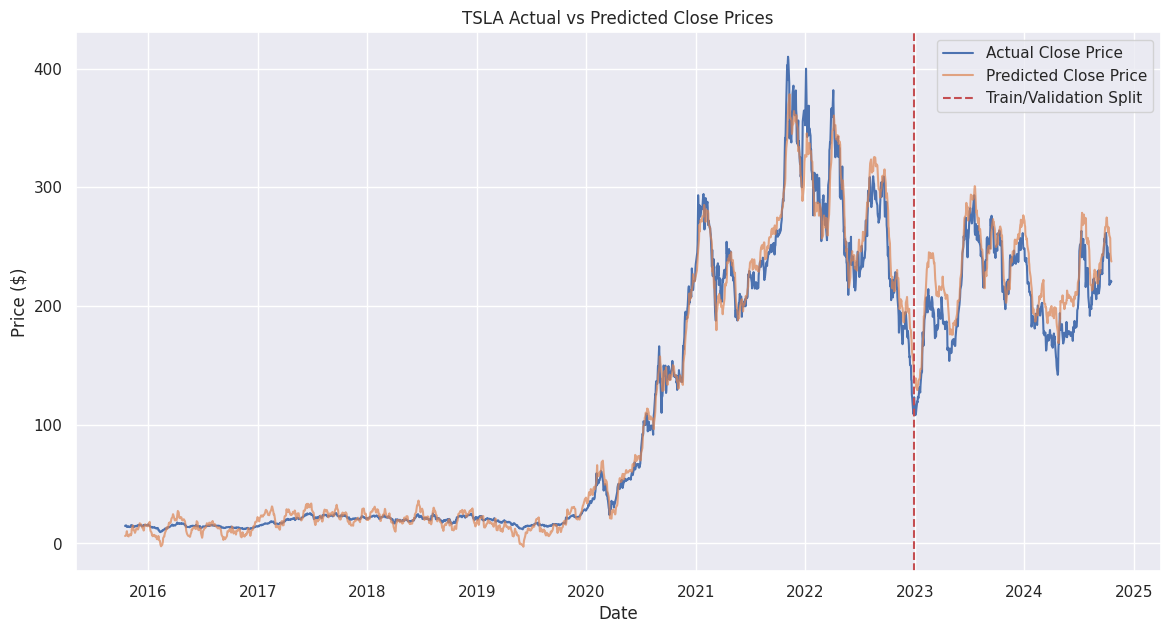


Validation RMSE for TSLA: 21.75
Validation MAE for TSLA: 18.31
Validation R-squared for TSLA: 0.6690

Overall RMSE for TSLA: 14.24
Overall MAE for TSLA: 9.78
Overall R-squared for TSLA: 0.9835


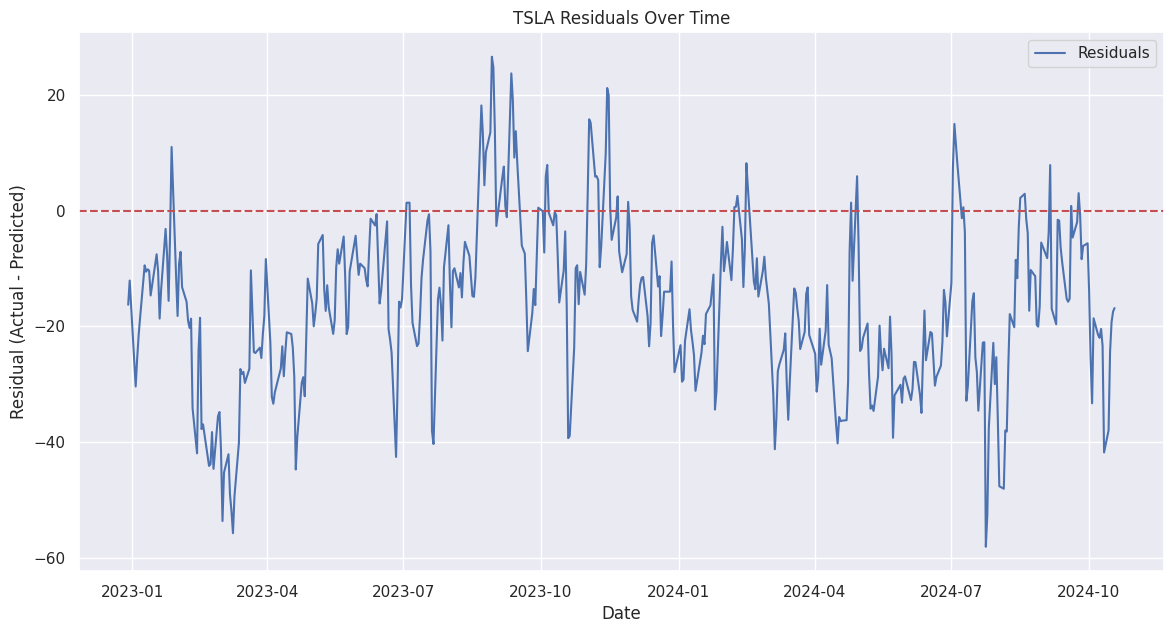

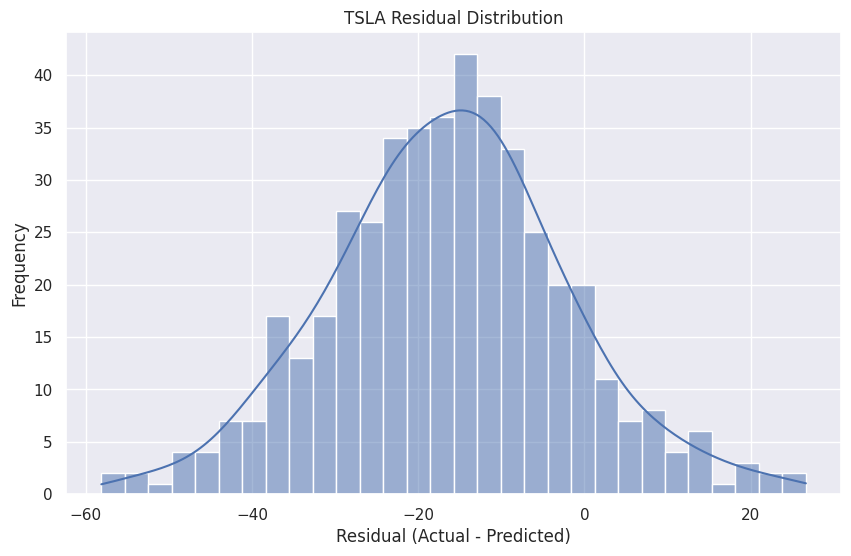


Predicted Close Price for next day: $235.37


In [77]:
# 1. Evaluate on validation set (already done)
# val_predictions, val_predictions_original, val_targets_original

# 2. Combine training and validation data for full predictions
X_combined = torch.cat((X_train[train_ticker], X_val[train_ticker]), dim=0)
Y_combined = torch.cat((Y_train[train_ticker], Y_val[train_ticker]), dim=0)

# Make predictions on combined data
combined_predictions = make_predictions(model, X_combined, device)
combined_predictions_original = inverse_transform(combined_predictions, scalers[train_ticker])
combined_targets_original = inverse_transform(Y_combined.cpu().numpy(), scalers[train_ticker])

# Get dates for the combined data
dates = technical_data[train_ticker]['Date'].values[SEQ_LENGTH:]  # Exclude initial sequence

# Plot full predictions
def plot_full_predictions(dates, actual, predicted, train_size, ticker):
    plt.figure(figsize=(14, 7))
    plt.plot(dates, actual, label='Actual Close Price')
    plt.plot(dates, predicted, label='Predicted Close Price', alpha=0.7)
    plt.axvline(x=dates[train_size], color='r', linestyle='--', label='Train/Validation Split')
    plt.title(f'{ticker} Actual vs Predicted Close Prices')
    plt.xlabel('Date')
    plt.ylabel('Price ($)')
    plt.legend()
    plt.show()

train_size = len(X_train[train_ticker])
plot_full_predictions(dates, combined_targets_original, combined_predictions_original, train_size, train_ticker)

# 3. Compute additional evaluation metrics
from sklearn.metrics import mean_absolute_error, r2_score

# Validation metrics
val_mae = mean_absolute_error(val_targets_original, val_predictions_original)
val_r2 = r2_score(val_targets_original, val_predictions_original)

print(f"\nValidation RMSE for {train_ticker}: {val_rmse:.2f}")
print(f"Validation MAE for {train_ticker}: {val_mae:.2f}")
print(f"Validation R-squared for {train_ticker}: {val_r2:.4f}")

# Overall metrics
rmse = calculate_rmse(combined_predictions_original, combined_targets_original)
mae = mean_absolute_error(combined_targets_original, combined_predictions_original)
r2 = r2_score(combined_targets_original, combined_predictions_original)

print(f"\nOverall RMSE for {train_ticker}: {rmse:.2f}")
print(f"Overall MAE for {train_ticker}: {mae:.2f}")
print(f"Overall R-squared for {train_ticker}: {r2:.4f}")

# 4. Analyze residuals
residuals = val_targets_original - val_predictions_original

def plot_residuals(dates, residuals, ticker):
    plt.figure(figsize=(14, 7))
    plt.plot(dates, residuals, label='Residuals')
    plt.axhline(y=0, color='r', linestyle='--')
    plt.title(f'{ticker} Residuals Over Time')
    plt.xlabel('Date')
    plt.ylabel('Residual (Actual - Predicted)')
    plt.legend()
    plt.show()

plot_residuals(val_dates, residuals, train_ticker)

def plot_residual_distribution(residuals, ticker):
    plt.figure(figsize=(10, 6))
    sns.histplot(residuals, bins=30, kde=True)
    plt.title(f'{ticker} Residual Distribution')
    plt.xlabel('Residual (Actual - Predicted)')
    plt.ylabel('Frequency')
    plt.show()

plot_residual_distribution(residuals, train_ticker)

# 5. Predict future prices
recent_data = technical_data[train_ticker].tail(SEQ_LENGTH)

if len(recent_data) == SEQ_LENGTH:
    features = ['Close', 'MA_50', 'MA_200', 'RSI_14', 'MACD_12_26_9', 'MACDh_12_26_9',
                'MACDs_12_26_9', 'BBL_20_2.0', 'BBM_20_2.0', 'BBU_20_2.0',
                'OBV']
    recent_features = recent_data[features].values
    recent_scaled = scalers[train_ticker].transform(recent_features)
    recent_input = torch.tensor(recent_scaled, dtype=torch.float32).unsqueeze(0).to(device)
    future_prediction = model(recent_input)
    future_prediction_original = inverse_transform(future_prediction.cpu().detach().numpy(), scalers[train_ticker])
    print(f"\nPredicted Close Price for next day: ${future_prediction_original[0]:.2f}")
else:
    print("Not enough data to make future prediction.")
